# 🧬 ViralGen AI: Hệ Thống Giám Sát Virus Thế Giới Mở (Open-World Surveillance)

**Mục tiêu nghiên cứu:** Xây dựng một đường ống (pipeline) trích xuất đặc trưng đa luồng (Multi-Kmer + TF-IDF) và ứng dụng Mạng nơ-ron học biểu diễn (Representation Learning) để không chỉ phân loại các biến thể SARS-CoV-2 đã biết, mà còn có khả năng tự động từ chối và cảnh báo khi gặp một mẫu gen chưa từng thấy (UNKNOWN_VARIANT).

## 1. Khởi Tạo Môi Trường Nghiên Cứu
Hệ thống sử dụng các công cụ toán học nâng cao:
* **TF-IDF:** Đánh giá trọng số đột biến gen.
* **Mahalanobis Distance:** Đo lường khoảng cách phân bố không gian đa chiều để phát hiện biến thể ngoại lai (Out-of-Distribution Detection).

In [1]:
# ==========================================
# 1. CÀI ĐẶT & IMPORT THƯ VIỆN (PYTORCH)
# ==========================================
!pip install biopython -q

import os
import itertools
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from Bio import SeqIO
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import IsolationForest

# --- PYTORCH IMPORTS ---
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# Bổ sung cho Open-World Pipeline
from sklearn.feature_extraction.text import TfidfTransformer
import scipy.linalg
from scipy.spatial.distance import mahalanobis

import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

print(f"PyTorch Version: {torch.__version__}")
# Cấu hình thiết bị: Ưu tiên dùng GPU nếu có trên Kaggle
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang sử dụng thiết bị tính toán: {device}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 51.2 MB/s eta 0:00:00
PyTorch Version: 2.10.0+cu128
Đang sử dụng thiết bị tính toán: cuda


## 2. Tiền Xử Lý Gen: Multi-Kmer & Chấm Điểm TF-IDF
Việc chỉ sử dụng một kích thước K-mer (ví dụ $K=4$) là không đủ "độ sâu" để phát hiện các đột biến phức tạp. 

**Cải tiến cốt lõi:**
1. **Multi-Kmer:** Trượt đồng thời 3 cửa sổ $K \in \{3, 4, 5\}$ dọc theo chuỗi DNA. Điều này tạo ra một không gian vector khổng lồ gồm 1344 chiều ($64 + 256 + 1024$), giúp hệ thống nhìn thấy cả các cụm đột biến ngắn và dài.
2. **TF-IDF (Term Frequency - Inverse Document Frequency):** Thay vì chỉ đếm số lần xuất hiện thuần túy, TF-IDF sẽ "phạt" (giảm điểm) các cụm gen quá phổ biến ở mọi loại virus, và "thưởng" (tăng điểm) cho các cụm K-mer hiếm gặp mang tính đột biến đặc trưng của từng chủng.

In [2]:
train_dir = '/kaggle/input/datasets/ducnguyen168/dataset-sars-cov-2-5-variants-tranminhgiakhanh'
# ==========================================
# 2. XỬ LÝ FASTA (MULTI-KMER & TF-IDF)
# ==========================================
NUCLEOTIDES = ['A', 'C', 'G', 'T']
# Tạo không gian 1344 chiều cho K=3, 4, 5
kmers_3 = [''.join(p) for p in itertools.product(NUCLEOTIDES, repeat=3)]
kmers_4 = [''.join(p) for p in itertools.product(NUCLEOTIDES, repeat=4)]
kmers_5 = [''.join(p) for p in itertools.product(NUCLEOTIDES, repeat=5)]
all_multi_kmers = kmers_3 + kmers_4 + kmers_5

def count_multi_kmers(sequence):
    seq_str = str(sequence).upper()
    kmer_counts = Counter()
    for k in [3, 4, 5]:
        kmers_in_seq = [seq_str[i:i+k] for i in range(len(seq_str) - k + 1)]
        kmer_counts.update(kmers_in_seq)
    return [kmer_counts.get(kmer, 0) for kmer in all_multi_kmers]

data_rows, labels = [], []
fasta_files = [os.path.join(dp, f) for dp, dn, filenames in os.walk(train_dir) 
               for f in filenames if f.lower().endswith(('.fasta', '.fa'))]
print(f"Đã tìm thấy {len(fasta_files)} file trong tập TRAIN (In-Distribution).")
print(f"Đang quét trình tự gen với Multi-Kmer (1344 chiều)...")
for file_path in fasta_files:
    label = os.path.splitext(os.path.basename(file_path))[0].split('_')[-1].capitalize()
    for record in SeqIO.parse(file_path, "fasta"):
        if len(record.seq) >= 25000:
            data_rows.append(count_multi_kmers(record.seq))
            labels.append(label)

# 1. Tạo DataFrame tần suất thô
df_raw = pd.DataFrame(data_rows, columns=all_multi_kmers)

# 2. Áp dụng TF-IDF để tôn vinh các đột biến hiếm
tfidf = TfidfTransformer()
X_tfidf = tfidf.fit_transform(df_raw.values).toarray()

# 3. Chuẩn hóa StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_tfidf)

y_raw = np.array(labels)
print(f"🎉 Hoàn tất! Kích thước ma trận: {X_scaled.shape[0]} mẫu, {X_scaled.shape[1]} đặc trưng (K=3,4,5).")

Đã tìm thấy 5 file trong tập TRAIN (In-Distribution).
Đang quét trình tự gen với Multi-Kmer (1344 chiều)...
🎉 Hoàn tất! Kích thước ma trận: 8500 mẫu, 1344 đặc trưng (K=3,4,5).


## 3. Khám Phá Cấu Trúc Dữ Liệu Bằng PCA (Không Gian Đa Chiều 1344D)
Hệ thống sử dụng thuật toán **PCA (Phân tích thành phần chính)** để nén 1344 đặc trưng (Multi-Kmer + TF-IDF) xuống còn không gian 2D. Bước này giúp chứng minh bằng trực giác rằng phương pháp TF-IDF đã hoạt động tốt trong việc kéo giãn khoảng cách giữa các cụm biến thể, làm tiền đề vững chắc cho hàng rào bảo vệ Mahalanobis ở các bước sau.

Đang nén không gian 1344 chiều xuống 2 chiều (PCA)...


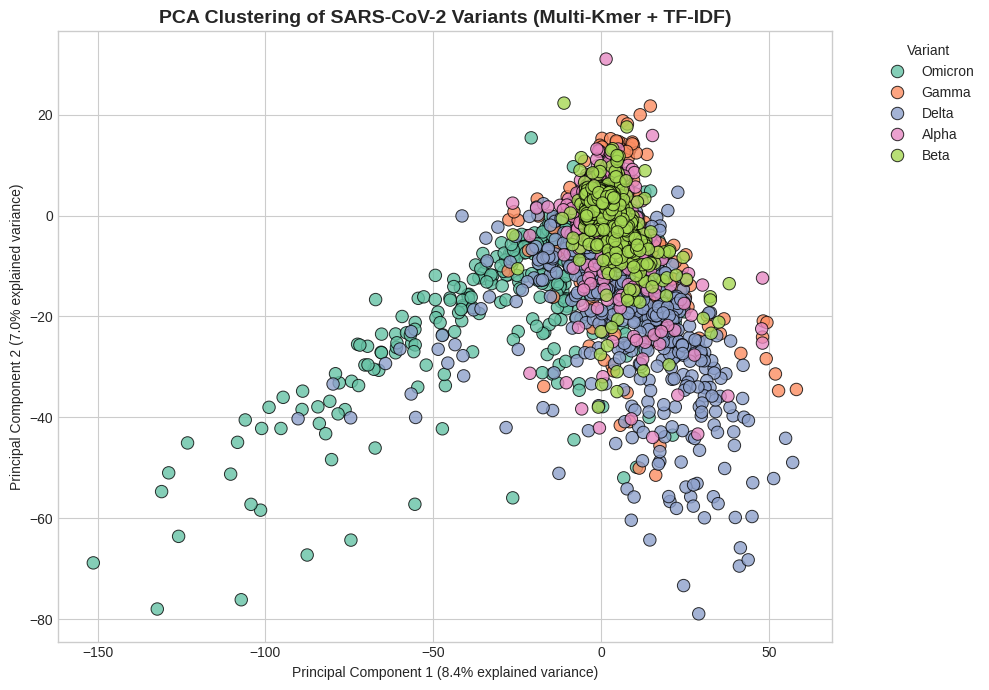

In [3]:
# ==========================================
# 3. TRỰC QUAN HÓA (EXPLORATORY DATA ANALYSIS)
# ==========================================
# Lưu ý: X_scaled và y_raw đã được tính toán và chuẩn bị sẵn từ Bước 2

print("Đang nén không gian 1344 chiều xuống 2 chiều (PCA)...")
# Giảm chiều dữ liệu xuống 2D bằng PCA để vẽ biểu đồ
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Vẽ biểu đồ phân cụm
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_raw, palette='Set2', s=80, alpha=0.8, edgecolor='k')

# Cập nhật tiêu đề phản ánh phương pháp mới
plt.title('PCA Clustering of SARS-CoV-2 Variants (Multi-Kmer + TF-IDF)', fontsize=14, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} explained variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} explained variance)')

# Đưa ghi chú (legend) ra ngoài để không che mất dữ liệu
plt.legend(title='Variant', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 4. Chuẩn Bị Dữ Liệu Huấn Luyện (Train/Test Split)
Để đánh giá mô hình khách quan, dữ liệu không được phép học thuộc lòng (overfitting). Chúng ta chia dataset làm hai phần độc lập:
* **Tập huấn luyện (Train - 80%):** Dùng để cung cấp kiến thức, giúp mạng nơ-ron điều chỉnh các trọng số (weights).
* **Tập kiểm thử (Test - 20%):** Hoàn toàn được giấu kín trong quá trình học. Chỉ dùng để thi và đo lường độ chính xác thực tế của hệ thống.
* **Mã hóa nhãn (Label Encoding):** Chuyển đổi tên biến thể dạng chữ (ví dụ: 'Alpha', 'Delta') thành các vector nhãn (One-hot encoding) để tương thích với hàm mất mát của hệ thống Deep Learning.

In [4]:
# ==========================================
# 4. CHUẨN BỊ DỮ LIỆU & DATALOADER
# ==========================================
# 1. Mã hóa nhãn (Ví dụ: Alpha -> 0, Delta -> 1)
le = LabelEncoder()
y_encoded = le.fit_transform(y_raw)
NUM_CLASSES = len(le.classes_)

# 2. Chia tập Train (80%) và Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 3. Chuyển đổi Numpy arrays sang PyTorch Tensors
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.LongTensor(y_train) # PyTorch yêu cầu LongTensor cho phân loại
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.LongTensor(y_test)

# 4. Tạo DataLoader để đưa dữ liệu vào mô hình theo từng lô (batch)
batch_size = 32
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Kích thước tập huấn luyện: {X_train.shape}")
print(f"Các lớp phân loại: {le.classes_}")

Kích thước tập huấn luyện: (6800, 1344)
Các lớp phân loại: ['Alpha' 'Beta' 'Delta' 'Gamma' 'Omicron']


## 5. Mạng Học Biểu Diễn (Representation Learning) & Label Smoothing
Đến đây, bài toán của chúng ta không còn là cố gắng phân loại đúng/sai nữa. Mạng Deep Learning lúc này đóng vai trò là một **Encoder** - thiết bị nén thông tin.
* Nó nhận vào không gian 1344 chiều và ép lại thành một không gian đặc trưng rất đặc (Dense Embedding) chỉ gồm **128 chiều**.
* **Label Smoothing (0.1):** Một "vũ khí" chống sự quá tự tin (overconfidence). Thay vì bắt mô hình học nhãn Delta là `[0, 1, 0, 0]`, nó sẽ bắt mô hình học `[0.025, 0.925, 0.025, 0.025]`. Việc giữ lại một chút hoài nghi giúp mô hình nhạy bén hơn khi gặp dữ liệu hoàn toàn lạ.

In [5]:
# ==========================================
# 5. OPEN-WORLD ENCODER & LABEL SMOOTHING
# ==========================================
class OpenWorldVirusEncoder(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(OpenWorldVirusEncoder, self).__init__()
        
        # BỘ TRÍCH XUẤT ĐẶC TRƯNG (Mục tiêu: Nén về 128D Embedding)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, 128), # <--- Không gian biểu diễn 128 chiều cốt lõi
            nn.ReLU()
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        embedding = self.encoder(x)
        logits = self.classifier(embedding)
        return logits, embedding

model = OpenWorldVirusEncoder(input_dim=X_train.shape[1], num_classes=NUM_CLASSES).to(device)

# ÁP DỤNG LABEL SMOOTHING (Mấu chốt chống Overconfidence)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Vòng lặp huấn luyện
epochs = 20
best_acc = 0.0
print("🚀 Đang huấn luyện mô hình Open-World Encoder...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits, _ = model(inputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits, _ = model(inputs)
            _, predicted = torch.max(logits.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
    epoch_acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {running_loss/len(train_loader):.4f} - Test Acc: {epoch_acc:.2f}%")
    if epoch_acc > best_acc:
        best_acc = epoch_acc
        torch.save(model.state_dict(), '/kaggle/working/open_world_encoder.pth')

🚀 Đang huấn luyện mô hình Open-World Encoder...
Epoch [1/20] - Loss: 0.4659 - Test Acc: 99.59%
Epoch [2/20] - Loss: 0.4106 - Test Acc: 99.71%
Epoch [3/20] - Loss: 0.4042 - Test Acc: 99.76%
Epoch [4/20] - Loss: 0.4030 - Test Acc: 99.41%
Epoch [5/20] - Loss: 0.3999 - Test Acc: 99.53%
Epoch [6/20] - Loss: 0.3991 - Test Acc: 99.59%
Epoch [7/20] - Loss: 0.3969 - Test Acc: 99.71%
Epoch [8/20] - Loss: 0.3954 - Test Acc: 99.76%
Epoch [9/20] - Loss: 0.3966 - Test Acc: 99.59%
Epoch [10/20] - Loss: 0.3952 - Test Acc: 99.76%
Epoch [11/20] - Loss: 0.3953 - Test Acc: 99.76%
Epoch [12/20] - Loss: 0.3943 - Test Acc: 99.76%
Epoch [13/20] - Loss: 0.3942 - Test Acc: 99.71%
Epoch [14/20] - Loss: 0.3948 - Test Acc: 99.82%
Epoch [15/20] - Loss: 0.3935 - Test Acc: 99.65%
Epoch [16/20] - Loss: 0.3951 - Test Acc: 99.59%
Epoch [17/20] - Loss: 0.3945 - Test Acc: 99.82%
Epoch [18/20] - Loss: 0.3937 - Test Acc: 99.59%
Epoch [19/20] - Loss: 0.3934 - Test Acc: 99.76%
Epoch [20/20] - Loss: 0.3953 - Test Acc: 99.29%


## 6. Đánh Giá Khả Năng Phân Loại Của Mạng Deep Learning
Trước khi sử dụng các đặc trưng 64 chiều (Feature Space) cho bước cảnh báo dị thường, chúng ta cần phải chứng minh mạng nơ-ron thực sự đã "hiểu" dữ liệu. Độ chính xác tổng thể (Accuracy) đôi khi không phản ánh hết bức tranh thực tế trong y sinh học. 

Hệ thống cung cấp hai công cụ đo lường chi tiết trên tập kiểm thử (Test Set):
1. **Classification Report:** Đánh giá các chỉ số Precision (Độ chuẩn xác) và Recall (Độ bao phủ) cho từng chủng virus.
2. **Confusion Matrix (Ma trận nhầm lẫn):** Một ma trận nhiệt (heatmap) hiển thị trực quan các ca đoán đúng (đường chéo chính) và cho thấy rõ hệ thống đang "nhầm lẫn" giữa các cặp biến thể nào có cấu trúc gen quá giống nhau.


=== Classification Report ===
              precision    recall  f1-score   support

       Alpha       1.00      1.00      1.00       400
        Beta       1.00      1.00      1.00       300
       Delta       1.00      1.00      1.00       400
       Gamma       1.00      1.00      1.00       400
     Omicron       0.99      0.99      0.99       200

    accuracy                           1.00      1700
   macro avg       1.00      1.00      1.00      1700
weighted avg       1.00      1.00      1.00      1700



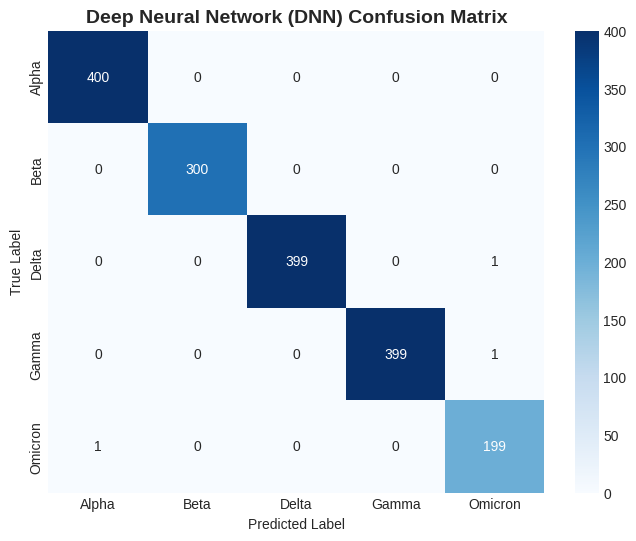

In [6]:
# ==========================================
# 6. ĐÁNH GIÁ ĐỘ CHÍNH XÁC PHÂN LOẠI (DNN EVALUATION)
# ==========================================
# Tải lại trọng số tốt nhất đã lưu ở Bước 5
model.load_state_dict(torch.load('/kaggle/working/open_world_encoder.pth'))
model.eval()

y_true_list = []
y_pred_list = []

# Suy luận trên toàn bộ tập test
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Lấy logits từ mạng Hybrid (bỏ qua features ở bước này)
        logits, _ = model(inputs) 
        _, predicted = torch.max(logits, 1)
        
        y_true_list.extend(labels.cpu().numpy())
        y_pred_list.extend(predicted.cpu().numpy())

print("\n=== Classification Report ===")
print(classification_report(y_true_list, y_pred_list, target_names=le.classes_))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_true_list, y_pred_list)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Deep Neural Network (DNN) Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

## 7. Thiết Lập "Hàng Rào" Mahalanobis (OOD Detection)
Thay vì dùng Isolation Forest, hệ thống sẽ sử dụng **Khoảng cách Mahalanobis** trong không gian 128 chiều. 
Khác với khoảng cách Euclid (đo đường chim bay), Mahalanobis xét đến cả hình dáng phân bố (Covariance) của cụm dữ liệu. Nó tính toán Tâm điểm (Centroid) và Ma trận Hiệp phương sai của từng biến thể đã biết. Nếu một mẫu gen rơi vào khoảng cách Mahalanobis $> 25.0$, hệ thống lập tức từ chối và xếp nó vào loại rủi ro bảo mật sinh học.

In [7]:
# ==========================================
# 7. TÍNH TOÁN KHÔNG GIAN MAHALANOBIS OOD
# ==========================================
model.load_state_dict(torch.load('/kaggle/working/open_world_encoder.pth'))
model.eval()

train_embeddings = []
train_labels_list = []

print("🔍 Đang tính toán Tâm điểm (Centroids) và Ma trận Hiệp phương sai...")
with torch.no_grad():
    for inputs, labels in train_loader:
        _, emb = model(inputs.to(device))
        train_embeddings.append(emb.cpu().numpy())
        train_labels_list.append(labels.numpy())

X_emb = np.vstack(train_embeddings)
y_emb = np.concatenate(train_labels_list)

class_stats = {}
for c in range(NUM_CLASSES):
    # Lấy ra tất cả các mẫu thuộc lớp 'c'
    X_c = X_emb[y_emb == c]
    
    # Tính Tâm (Centroid)
    centroid = np.mean(X_c, axis=0)
    
    # Tính Ma trận hiệp phương sai. Cộng thêm 1e-6 để tránh lỗi suy biến (Singular Matrix)
    cov_matrix = np.cov(X_c, rowvar=False) + np.eye(128) * 1e-6 
    cov_inv = scipy.linalg.pinvh(cov_matrix) # Giả nghịch đảo
    
    class_stats[c] = {'centroid': centroid, 'cov_inv': cov_inv}

print("✅ Đã thiết lập xong màng lọc OOD Mahalanobis cho", NUM_CLASSES, "cộng đồng gen.")

🔍 Đang tính toán Tâm điểm (Centroids) và Ma trận Hiệp phương sai...
✅ Đã thiết lập xong màng lọc OOD Mahalanobis cho 5 cộng đồng gen.


## 8. Chẩn Đoán Thực Tế: Uncertainty & MC Dropout
Đây là lúc hệ thống trổ tài. Khi nạp một mẫu `.fasta` thực tế:
1. **MC Dropout:** Mạng DNN chạy 30 lần liên tiếp (Không tắt chế độ nhiễu Dropout). Nếu 30 lần mạng trả ra các kết quả quá khác nhau $\rightarrow$ Độ bất định (Uncertainty) cao $\rightarrow$ Chủng lạ.
2. **Temperature Scaling ($T=3.0$):** Hạ nhiệt độ hàm Softmax để con số % thực tế và khiêm tốn hơn.
3. **Phán Quyết Mahalanobis:** Nếu mẫu này nằm cách quá xa mọi tâm điểm đã học, nó sẽ tự động bị gắn nhãn **`UNKNOWN_VARIANT`** thay vì cố gắng đoán bừa.

In [8]:
# ==========================================
# 8. OPEN-WORLD INFERENCE (TEST MẪU FASTA LẠ)
# ==========================================
TEST_FILE_PATH = '/kaggle/input/datasets/ducnguyen168/dataset-test-c-37-lambda/sequences_20260513_5937962_C.37' # File bạn cần test

def enable_dropout(m):
    if type(m) == nn.Dropout: m.train()

def open_world_inference(file_path, T=3.0, mc_passes=30, mahalanobis_threshold=25.0):
    if not os.path.exists(file_path):
        print("⚠️ Không tìm thấy file!")
        return

    # Tiền xử lý
    record = next(SeqIO.parse(file_path, "fasta"))
    features_raw = count_multi_kmers(record.seq)
    features_tfidf = tfidf.transform([features_raw]).toarray()
    features_scaled = scaler.transform(features_tfidf)
    sample_tensor = torch.FloatTensor(features_scaled).to(device)
    
    # Bật MC Dropout
    model.eval()
    model.apply(enable_dropout) 
    
    mc_logits, mc_embeddings = [], []
    with torch.no_grad():
        for _ in range(mc_passes): # Chạy 30 lần lấy mẫu
            logits, emb = model(sample_tensor)
            mc_logits.append(logits.cpu().numpy()[0])
            mc_embeddings.append(emb.cpu().numpy()[0])
            
    # 1. TEMPERATURE SCALING 
    mean_logits = np.mean(mc_logits, axis=0)
    scaled_logits = mean_logits / T
    exp_logits = np.exp(scaled_logits - np.max(scaled_logits))
    probs = exp_logits / exp_logits.sum()
    
    pred_class = np.argmax(probs)
    confidence = probs[pred_class]
    prediction_variance = np.var(mc_logits, axis=0).mean() # Đo độ dao động (Uncertainty)
    
    # 2. ĐO KHOẢNG CÁCH MAHALANOBIS
    mean_embedding = np.mean(mc_embeddings, axis=0)
    stats = class_stats[pred_class]
    dist = mahalanobis(mean_embedding, stats['centroid'], stats['cov_inv'])
    
    print("\n" + "="*50)
    print("🌍 KẾT QUẢ GIÁM SÁT THẾ GIỚI MỞ (OPEN-WORLD)")
    print("="*50)
    print(f"🧬 File phân tích: {os.path.basename(file_path)}")
    print(f"🔸 Hình thái giống nhất với lớp: {le.inverse_transform([pred_class])[0]}")
    print(f"🔸 Độ tự tin (Temperature Scaled): {confidence:.2%}")
    print(f"🔸 Độ dao động suy luận (MC Variance): {prediction_variance:.4f}")
    print(f"🔸 Khoảng cách Mahalanobis: {dist:.2f} (Ngưỡng an toàn < {mahalanobis_threshold})")
    print("-" * 50)
    
    # QUYẾT ĐỊNH
    if dist > mahalanobis_threshold or prediction_variance > 1.5:
        print("🚨 BÁO ĐỘNG ĐỎ: ĐÃ VƯỢT NGƯỠNG AN TOÀN!")
        print("-> HỆ THỐNG TRẢ VỀ: [ UNKNOWN_VARIANT ] - CHỦNG MỚI CHƯA TỪNG HUẤN LUYỆN.")
    else:
        print(f"✅ KẾT LUẬN: Mẫu gen an toàn. Thuộc quần thể [{le.inverse_transform([pred_class])[0]}].")

# Uncomment dòng dưới để chạy test
open_world_inference(TEST_FILE_PATH)


🌍 KẾT QUẢ GIÁM SÁT THẾ GIỚI MỞ (OPEN-WORLD)
🧬 File phân tích: sequences_20260513_5937962_C.37
🔸 Hình thái giống nhất với lớp: Omicron
🔸 Độ tự tin (Temperature Scaled): 48.47%
🔸 Độ dao động suy luận (MC Variance): 0.0187
🔸 Khoảng cách Mahalanobis: 256.76 (Ngưỡng an toàn < 25.0)
--------------------------------------------------
🚨 BÁO ĐỘNG ĐỎ: ĐÃ VƯỢT NGƯỠNG AN TOÀN!
-> HỆ THỐNG TRẢ VỀ: [ UNKNOWN_VARIANT ] - CHỦNG MỚI CHƯA TỪNG HUẤN LUYỆN.


### 9. Đánh giá khả năng phát hiện Thế giới mở (Open-World / OOD Detection)

Trong phần này, chúng ta sẽ định lượng khả năng của mô hình trong việc phân biệt các chủng đã học (**In-Distribution - IND**) và các chủng chưa từng thấy (**Out-of-Distribution - OOD**). 

Chúng ta sử dụng 3 thang đo tiêu chuẩn thường được dùng trong các bài báo khoa học về độ tin cậy của AI:
1. **Biểu đồ phân phối (Histogram):** Đánh giá trực quan sự tách biệt giữa hai tập dữ liệu.
2. **AUROC (Area Under the Receiver Operating Characteristic curve):** Khả năng phân loại tổng quát. AUROC $\approx 0.5$ là đoán ngẫu nhiên, AUROC $> 0.9$ là xuất sắc.
3. **FPR@TPR95 (FPR95):** Tỷ lệ dương tính giả (nhận nhầm chủng gốc thành chủng lạ) khi chúng ta cố định độ nhạy phát hiện chủng lạ ở mức 95%. FPR95 càng thấp càng chứng tỏ hệ thống an toàn và ít báo động giả.

Chúng ta sẽ dùng **Khoảng cách Mahalanobis** làm "Điểm số bất thường" (Anomaly Score).

In [9]:
# ==========================================
# 9.1. NẠP VÀ TIỀN XỬ LÝ TẬP TEST (TÁCH BIỆT IND VÀ OOD)
# ==========================================
print("📥 Đang nạp dữ liệu Test...")

test_ind_dir = '/kaggle/input/datasets/ducnguyen168/dataset-test-sars-cov-2-5-variants/dataset_test/IND'
test_ood_dir = '/kaggle/input/datasets/ducnguyen168/dataset-test-sars-cov-2-5-variants/dataset_test/OOD'

def process_test_folder(folder_path):
    """Hàm nạp và transform dữ liệu cho một thư mục test cụ thể"""
    files = [os.path.join(dp, f) for dp, dn, filenames in os.walk(folder_path) 
             for f in filenames if f.lower().endswith(('.fasta', '.fa'))]
    
    rows = []
    for file_path in files:
        for record in SeqIO.parse(file_path, "fasta"):
            if len(record.seq) >= 25000:
                rows.append(count_multi_kmers(record.seq))
                
    # Ép không gian theo tập Train và Transform
    df_test = pd.DataFrame(rows, columns=all_multi_kmers).fillna(0)
    X_tfidf = tfidf.transform(df_test.values).toarray()
    X_scaled = scaler.transform(X_tfidf)
    return X_scaled

# Nạp riêng 2 tập
X_test_ind = process_test_folder(test_ind_dir)
X_test_ood = process_test_folder(test_ood_dir)

print(f"✅ Kích thước Test IND: {X_test_ind.shape[0]} mẫu")
print(f"✅ Kích thước Test OOD: {X_test_ood.shape[0]} mẫu")

📥 Đang nạp dữ liệu Test...
✅ Kích thước Test IND: 1000 mẫu
✅ Kích thước Test OOD: 800 mẫu


### 9.1. Đột phá với Học Biểu Diễn (Representation Learning) & Không gian Mahalanobis Tiềm Ẩn

Ở các thử nghiệm trước, việc đo lường độ bất thường trực tiếp trên không gian đặc trưng nguyên thủy (TF-IDF với 1344 chiều) đã bộc lộ giới hạn. Hiện tượng ma trận thưa (sparsity) và **lời nguyền số chiều (curse of dimensionality)** đã tạo ra nhiều nhiễu, khiến thuật toán đo khoảng cách tuyến tính gặp khó khăn trong việc tách biệt các biến thể.

Để phá vỡ giới hạn này, chúng ta sẽ áp dụng một trong những kỹ thuật hiện đại nhất trong OOD Detection: **Kết hợp Mạng Nơ-ron Học Biểu Diễn (Deep Feature Extraction) với mô hình khoảng cách sinh mẫu (Generative Distance Modeling)**. Thay vì dùng dữ liệu thô, chúng ta sẽ dùng mạng Nơ-ron đã được huấn luyện để nén thông tin gen thành các vector tinh khiết nhất.

**Đoạn code dưới đây sẽ thực hiện 3 bước cốt lõi:**
1. **Ép kiểu đặc trưng (Latent Space Extraction):** Đưa dữ liệu qua mạng `OpenWorldVirusEncoder` (ở chế độ `eval` để đóng băng trọng số). Chúng ta sẽ bỏ qua lớp phân loại cuối cùng, chỉ lấy vector đặc trưng ở lớp áp chót (**Penultimate Layer - 128 chiều**). Không gian 128D này là nơi mạng nơ-ron đã tự động chắt lọc ra những đặc tính sinh học quan trọng nhất của các chủng virus quen thuộc.
2. **Định hình quần thể (Distribution Modeling):** Tính toán vector Trung bình (Mean) và Ma trận nghịch đảo hiệp phương sai (Inverse Covariance Matrix) của tập **Train** ngay trên không gian 128D này.
3. **Chấm điểm bất thường (Anomaly Scoring):** Sử dụng **Khoảng cách Mahalanobis** để đo xem các mẫu thuộc tập Test (IND và OOD) nằm cách xa "vùng lõi" quần thể bao nhiêu. Các chủng virus lạ (OOD) sẽ sinh ra các vector đặc trưng không khớp với những gì mạng đã học, do đó khoảng cách Mahalanobis của chúng sẽ tăng vọt.

In [10]:
import scipy
from scipy.spatial.distance import mahalanobis
import torch

# ==========================================
# 9.2. TRÍCH XUẤT EMBEDDING & TÍNH KHOẢNG CÁCH MAHALANOBIS (TÙY CHỌN 2)
# ==========================================
print("🧠 Đang ép dữ liệu đi qua Mạng Học Biểu Diễn (128D)...")

# Chuyển đổi dữ liệu Test sang PyTorch Tensors
X_test_ind_tensor = torch.FloatTensor(X_test_ind).to(device)
X_test_ood_tensor = torch.FloatTensor(X_test_ood).to(device)

model.eval()
with torch.no_grad():
    # 1. Trích xuất Embedding cho tập TRAIN (Dùng X_train - 80% dữ liệu ở Cell 4 làm mốc)
    _, train_embeds = model(torch.FloatTensor(X_train).to(device))
    train_embeds = train_embeds.cpu().numpy()
    
    # 2. Trích xuất Embedding cho tập Test IND và Test OOD
    _, test_ind_embeds = model(X_test_ind_tensor)
    test_ind_embeds = test_ind_embeds.cpu().numpy()
    
    _, test_ood_embeds = model(X_test_ood_tensor)
    test_ood_embeds = test_ood_embeds.cpu().numpy()

print(f"✅ Kích thước không gian mới: Train IND {train_embeds.shape}, Test OOD {test_ood_embeds.shape}")

# ------------------------------------------
# TÍNH TOÁN MAHALANOBIS TRÊN KHÔNG GIAN 128D
# ------------------------------------------
print("🧮 Đang tính toán Ma trận hiệp phương sai...")

# Tính phân bố (Mean, Cov) dựa trên TẬP TRAIN EMBEDDINGS
train_mean = np.mean(train_embeds, axis=0)
train_cov = np.cov(train_embeds, rowvar=False)
train_inv_cov = scipy.linalg.pinv(train_cov)

def get_mahalanobis_scores(X_embed, mean_vec, inv_cov_matrix):
    return np.array([mahalanobis(x, mean_vec, inv_cov_matrix) for x in X_embed])

# TÍNH ĐIỂM BẤT THƯỜNG (ANOMALY SCORE) CHO TẬP TEST
test_ind_scores = get_mahalanobis_scores(test_ind_embeds, train_mean, train_inv_cov)
test_ood_scores = get_mahalanobis_scores(test_ood_embeds, train_mean, train_inv_cov)

print("✅ Đã tính xong điểm số Mahalanobis!")

🧠 Đang ép dữ liệu đi qua Mạng Học Biểu Diễn (128D)...
✅ Kích thước không gian mới: Train IND (6800, 128), Test OOD (800, 128)
🧮 Đang tính toán Ma trận hiệp phương sai...
✅ Đã tính xong điểm số Mahalanobis!


### 9.2. Định lượng hiệu suất bằng AUROC và FPR95

Thay vì chỉ nhìn bằng mắt, chúng ta dùng ROC Curve để đánh giá chi tiết:
* Trục Y là **TPR (True Positive Rate)**: Tỷ lệ bắt trúng chủng lạ.
* Trục X là **FPR (False Positive Rate)**: Tỷ lệ báo động nhầm.

Để tính $FPR95$, ta tìm ngưỡng (threshold) của khoảng cách Mahalanobis sao cho TPR vừa đủ đạt 95%, sau đó dóng xuống trục X để xem FPR tương ứng là bao nhiêu. Trong thực tế lâm sàng hoặc giám sát sinh học, $FPR95$ thấp là yếu tố then chốt để tránh làm quá tải hệ thống cảnh báo.

🎯 BÁO CÁO KẾT QUẢ OOD DETECTION
🔹 AUROC: 0.9892
🔹 FPR95: 0.0370
🔹 Ngưỡng Mahalanobis tại TPR=95%: 30.16


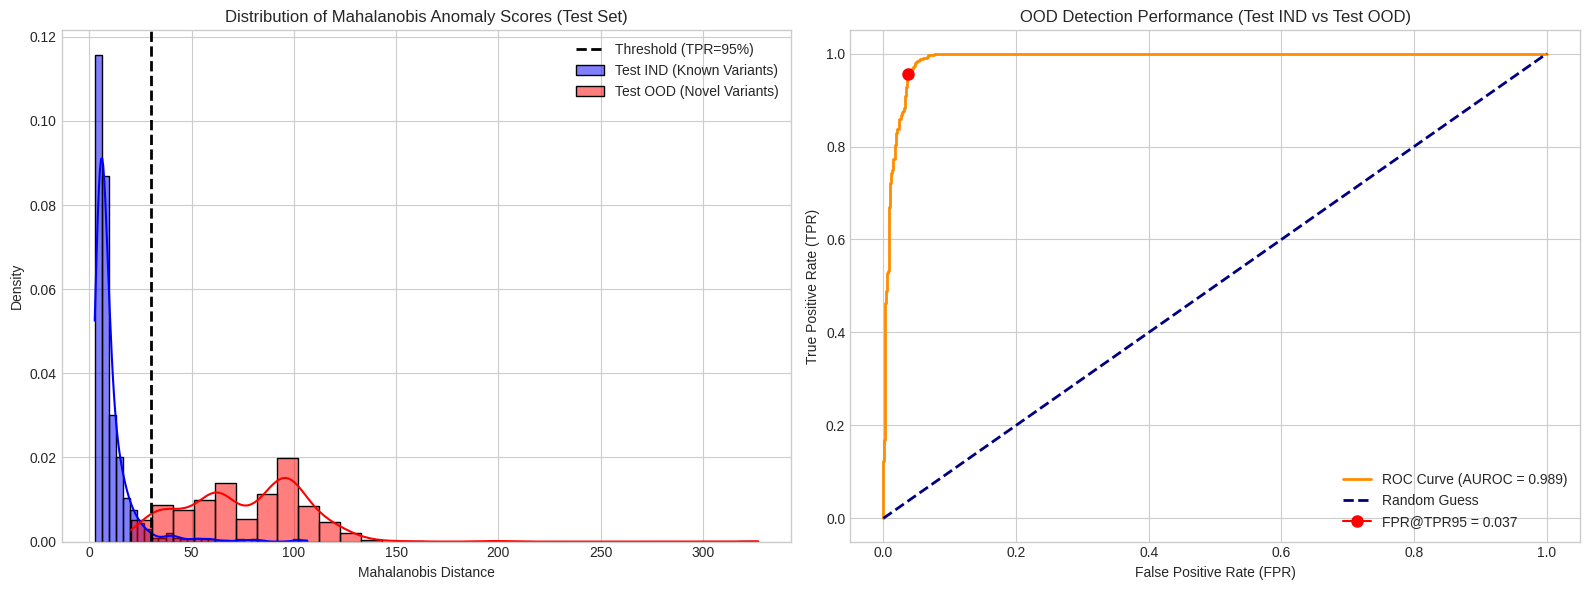

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

# ==========================================
# 9.3. TÍNH METRICS (AUROC, FPR95) VÀ VẼ BIỂU ĐỒ
# ==========================================
# Chuẩn hóa nhãn lúc này: 0 cho Test IND (Bình thường), 1 cho Test OOD (Bất thường)
y_true = np.concatenate([np.zeros(len(test_ind_scores)), np.ones(len(test_ood_scores))])
y_scores = np.concatenate([test_ind_scores, test_ood_scores])

# Tính ROC, AUROC
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
auroc = roc_auc_score(y_true, y_scores)

# Tìm ngưỡng FPR95
idx_95 = np.where(tpr >= 0.95)[0][0]
fpr95 = fpr[idx_95]
threshold_95 = thresholds[idx_95]

print("="*40)
print("🎯 BÁO CÁO KẾT QUẢ OOD DETECTION")
print("="*40)
print(f"🔹 AUROC: {auroc:.4f}")
print(f"🔹 FPR95: {fpr95:.4f}")
print(f"🔹 Ngưỡng Mahalanobis tại TPR=95%: {threshold_95:.2f}")
print("="*40)

# Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(test_ind_scores, color='blue', label='Test IND (Known Variants)', kde=True, stat="density", bins=30, ax=axes[0])
sns.histplot(test_ood_scores, color='red', label='Test OOD (Novel Variants)', kde=True, stat="density", bins=30, ax=axes[0])
axes[0].axvline(threshold_95, color='black', linestyle='dashed', linewidth=2, label='Threshold (TPR=95%)')
axes[0].set_title('Distribution of Mahalanobis Anomaly Scores (Test Set)')
axes[0].set_xlabel('Mahalanobis Distance')
axes[0].legend()

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUROC = {auroc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
axes[1].plot(fpr95, tpr[idx_95], marker='o', markersize=8, color='red', label=f'FPR@TPR95 = {fpr95:.3f}')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].set_title('OOD Detection Performance (Test IND vs Test OOD)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()